In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

#Data folder:
#folder = r'C:\Users\vanan\OneDrive\Desktop\Pit Propagation Model\Single Pit Growth\processed_data'
folder = '/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/data/processed_data'
import_file = 'data_along_pit_surface.csv'
export_filename = 'data_along_pit_nearest_neighbor_Pit'

#folder = '/glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/post_test/csvtest'
#import_file = 'unorg_0_only.csv'
#import_file = 'all_nn_data_1.csv'

### Get the curre:w
# nt working directory
cwd = os.getcwd()
print("Current working directory: {0}".format(cwd))

### Change directory to data folder for each simulation
os.chdir(folder)
cwd = os.getcwd()
print("Current working directory: {0}".format(cwd))

### Import the data file:
df = pd.read_csv(import_file,index_col=0) 
t_list = df['t'].unique()

t_list2 = t_list.tolist()

ind1 = t_list2.index(5)
#ind1 = t_list2.index(0.10679)
#ind1 = t_list2.index(0.20317)
#ind1 = t_list2.index(0.30474)
#ind1 = t_list2.index(0.40364)
#ind1 = t_list2.index(0.70033)
#ind1 = t_list2.index(0.80552)
#ind1 = t_list2.index(0.9019)
#ind1 = t_list2.index(1.3034)
t = t_list[ind1] #<-------------------------------------------------Change time to process the data in here
#print(t_list2)
print(ind1)
print(t_list)
print('Select time:',t)

Current working directory: /glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/Pitting_Corrosion/postproc/PostProcessingCode
Current working directory: /glb/data/drs1/users/Bangalore/invmfj/iterativeRecon/B1M4/mlem_test/fdk_centershift/rocks/json/comsol_batch/data/processed_data
5
[4.1123  3.2134  2.8015  4.6179  0.40035 0.      4.0187  3.6067  1.6072
 3.9063  2.9138  0.50439 2.1065  0.20269 1.7008  0.80609 1.8048  4.9175
 0.91012 0.70205 4.4119  3.3071  2.2002  2.4082  1.9089  0.10385 3.0075
 4.3183  2.5019  3.7003  2.7078  5.      1.5031  1.1078  1.4095  1.3055
 1.2014  3.1011  3.8127  4.2059  1.0038  2.3042  0.60842 4.7115  4.8052
 3.5131  3.4007  2.0025  0.30152 2.6059  4.5056 ]
Select time: 0.0


In [2]:
## Re-arrange data to to show order along the pit surface

df_t = df[df['t']==t] # original

### Test ####################
'''vars_list= ['x', 'y', 'cMe', 'phil', 'phipf','phis','I','iloc','t']
inFile = 'data_0s.txt'
df_actual = pd.read_csv(inFile, sep="\t", header=None)
df_actual.columns = vars_list

df_xline = df[df['x'].between(-7e-5,7e-5)]
df_t = df_xline[df_xline.y <= 0.0] #No filter the phipf variables (two phases are included)
'''
##############################
df_t.index = np.arange(1,len(df_t)+1)
df_t['cord'] = list(zip(df_t.x, df_t.y))
df_t_sub = df_t.iloc[:,[0,1,-1]].sort_values(by=['y','x'],ascending=False)
# testing
#print(df_t.iloc[0,[0,1,2,-1]])
print(df_t_sub.loc[1])

n = df_t.shape[0]
l_dict = {}

for i in np.arange(1,n+1):
    for j in np.arange(i+1,n+1):
        x1,y1,_ = df_t_sub.loc[i]
        x2,y2,_ = df_t_sub.loc[j]
        l = np.sqrt((x2-x1)**2+(y2-y1)**2)
        l_dict[(i,j)]=[l,0]
        l_dict[(j, i)] = [l, 0]
    l_dict[(i, i)] = [0,1]

### Find the nearest neighbors for each points, given the start points coordinate of the path:
start_point_cord =df_t_sub.iloc[0,-1]
start_point_idx = df_t_sub.index[df_t_sub['cord']==start_point_cord].to_list()[0]
print('Start point (idx,x,y):',start_point_idx,start_point_cord)

point_list_idx = np.arange(1,n+1)
next_point_idx = 0
previous_point_idx = 0
l_total = 0
j=0
is_seen = 0
point_seen =[]
l_total_list =[]
while True:
    l_min = 10
    # Start point is fixed for the entire duration of the for loop. Suppose start point idx is 238. In the loop, the distance from this
    # point to every other point in the list is checked. At each target point with index i, the distance of the pair l_dist(i,238) is checked.
    # If an i is found such that the distance l_min so far is smaller than the prvious value, then this i point is assigned as next point. The loop repeats like this
    # until all the other points are checked. Finally, start point is assigned to previous point, and the next point label becomes the new start point and the loop
    # repeats again from i = 1. 
    for i in point_list_idx:
        if i not in point_seen:
            cord = (i,start_point_idx)
            reverse_cord = (start_point_idx,i)
            l =l_dict[cord][0]
            is_seen = l_dict[cord][1]
            #print(cord,l_dict[cord])

            if (is_seen==0) & (l_min>l):
                l_min = l
                next_point_idx=i
                l_dict[cord][1] = 1
                l_dict[reverse_cord][1] = 1

    previous_point_idx = start_point_idx
    point_seen.append(previous_point_idx)
    start_point_idx = next_point_idx

    l_total+=l_min
    l_total_list.append(l_total)

    #print('previous point',previous_point_idx,',start point',start_point_idx,',min distance:',round(l_min,8),',total length',round(l_total,8))
    j+=1
    #if j==n-1: #j==n-1:
    if j==n: #j==n-1:
       break

#check points seen, l total list, and dimension:
u, c = np.unique(point_seen, return_counts=True)
print('Duplicate:',u[c>1])

df_t_reindex = df_t.reindex(point_seen)
df_t_reindex['l_accum']=l_total_list

print('#point seen:',len(point_seen), 'len l_total_list:',len(l_total_list))
print('#rows in df_t:',n)
print('Shape of df_t_reindex:',df_t_reindex.shape)
print('Total perimeters (microns)',l_total)

/tmp/ipykernel_31737/195800517.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_t['cord'] = list(zip(df_t.x, df_t.y))


x                  -0.000002
y                  -0.000003
cord    (-1.9e-06, -2.5e-06)
Name: 1, dtype: object
Start point (idx,x,y): 74 (9e-07, -1e-07)
Duplicate: []
#point seen: 74 len l_total_list: 74
#rows in df_t: 74
Shape of df_t_reindex: (74, 11)
Total perimeters (microns) 10.00001105685425


In [3]:
#Export processed data to csv
export_filename_csv = export_filename+'_'+str(round(t,2))+'.csv'
df_t_reindex.to_csv(export_filename_csv)
print('Complete export df_t_reindex (processed data):',export_filename_csv)


Complete export df_t_reindex (processed data): data_along_pit_nearest_neighbor_Pit_0.0.csv


The original datasest:


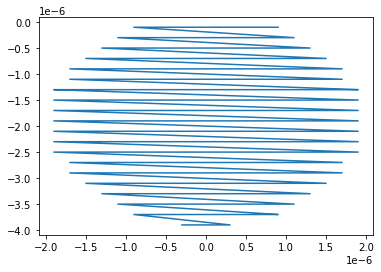

In [4]:
### Plot the pit shapes and parameters vs pit length
print('The original datasest:')
plot1 = plt.figure(1) #plot of the original data
plt.plot(df_t_sub.x,df_t_sub.y)
plt.show()

Processed data after rearranged based on the nearest neighbor


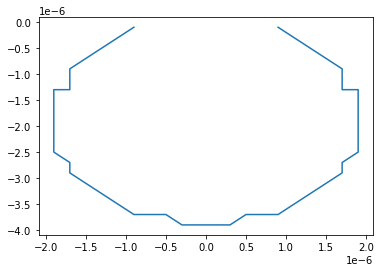

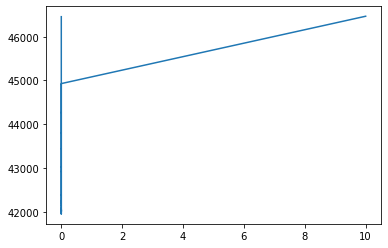

In [5]:
print('Processed data after rearranged based on the nearest neighbor')
plot2 = plt.figure(2) #plot of the processed data after rearranged based on the nearest neighbor
plt.plot(df_t_reindex.x,df_t_reindex.y)

plt3=plt.figure(3) #plot of local c.d vs pit length
plt.plot(df_t_reindex['l_accum'],df_t_reindex['iloc'])

plt.show()
#print(l_dict)